In [1]:
# ============ ИМПОРТЫ ============
import pandas as pd
import numpy as np
import lightgbm as lgb
import holidays
import matplotlib.pyplot as plt
import time
import seaborn as sns

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (14, 6)

print("Импорты загружены")

Импорты загружены


In [2]:
# ============ ЗАГРУЗКА ДАННЫХ =======================================

# --------------------------ВЫБОР_РЕГИОНА-----------------------------
# --------------------------------------------------------------------
file_path = 'drive/MyDrive/Colab Notebooks/combined.csv'
# --------------------------------------------------------------------
# --------------------------------------------------------------------

df = pd.read_csv(file_path)
df['date'] = pd.to_datetime(df['date'])
df = df.set_index('date').sort_index()

print(f"Форма: {df.shape}")
print(f"Период: {df.index.min()} — {df.index.max()}")
print(f"Пропуски:\n{df.isnull().sum()}")
print("\nПервые строки:")
print(df.head())

Форма: (39721, 5)
Период: 2022-01-01 00:00:00 — 2026-09-23 22:00:00
Пропуски:
planned_consumption    0
actual_consumption     0
planned_generation     0
actual_generation      0
average_price          0
dtype: int64

Первые строки:
                     planned_consumption  actual_consumption  \
date                                                           
2022-01-01 00:00:00                 4076                4051   
2022-01-01 01:00:00                 4107                4124   
2022-01-01 02:00:00                 4063                4133   
2022-01-01 03:00:00                 3986                4024   
2022-01-01 04:00:00                 4046                3994   

                     planned_generation  actual_generation  average_price  
date                                                                       
2022-01-01 00:00:00                3344               3332            935  
2022-01-01 01:00:00                3163               3161            863  
2022-01-01 02:0

In [3]:
# ============ ОЧИСТКА ДАННЫХ ============
rows_before = len(df)

df = df[(df['actual_consumption'] > 0) &
        (df['actual_generation'] > 0) &
        (df['planned_consumption'] > 0) &
        (df['planned_generation'] > 0)]

rows_after = len(df)
print(f"Строк до очистки:   {rows_before}")
print(f"Строк после очистки: {rows_after}")
print(f"Удалено:            {rows_before - rows_after} строк")

print("\nПроверка после очистки:")
print(f"Нули в actual_consumption: {(df['actual_consumption'] == 0).sum()}")
print(f"Нули в actual_generation:  {(df['actual_generation'] == 0).sum()}")
print(f"Минимум actual_consumption: {df['actual_consumption'].min():.0f} МВт")
print(f"Максимум actual_consumption: {df['actual_consumption'].max():.0f} МВт")

Строк до очистки:   39721
Строк после очистки: 39714
Удалено:            7 строк

Проверка после очистки:
Нули в actual_consumption: 0
Нули в actual_generation:  0
Минимум actual_consumption: 3132 МВт
Максимум actual_consumption: 5675 МВт


In [4]:
"""Единое разбиение данных (одинаковое для всех моделей проекта).

Протокол: скользящее окно (rolling origin) на один год.
Для каждого дня D прогнозного периода обучающая выборка = все сутки,
которые закончились ДО дня D (с начала данных до D-1 включительно).
Например, для 2 января обучение включает 1 января; для 1 января - всё до 31 декабря.
Данные дня D и позже в обучение не попадают.
"""
import numpy as np
import pandas as pd

FORECAST_START = '2025-01-01'
FORECAST_END = '2025-12-31'


def forecast_day_indices(days, start=FORECAST_START, end=FORECAST_END):
    """Индексы суток прогнозного периода внутри массива days."""
    mask = (days >= pd.Timestamp(start)) & (days <= pd.Timestamp(end))
    return np.where(mask)[0]


def rolling_origin(days, start=FORECAST_START, end=FORECAST_END, window_days=None):
    """Генератор (i, train_idx): i - индекс прогнозируемых суток,
    train_idx - индексы суток, доступных для обучения.

    window_days=None  - расширяющееся окно (всё с начала данных до D-1);
    window_days=N     - только последние N суток перед D (более короткий период).
    """
    for i in forecast_day_indices(days, start, end):
        lo = 0 if window_days is None else max(0, i - window_days)
        yield i, np.arange(lo, i)


def fixed_origin(days, start=FORECAST_START, end=FORECAST_END):
    """Одно обучение на всех сутках ДО начала прогнозного периода
    (старая постановка, для сравнения). Возвращает (train_idx, test_idx)."""
    test_idx = forecast_day_indices(days, start, end)
    train_idx = np.arange(0, test_idx[0])
    return train_idx, test_idx

In [5]:
# ============ ПРОВЕРКА ДАННЫХ ============
df['hourly_diff'] = df['actual_consumption'].diff().abs()
big_jumps = df[df['hourly_diff'] > 500]
print(f"1. Скачков >500 МВт/час: {len(big_jumps)}")

df['is_same'] = (df['actual_consumption'] == df['actual_consumption'].shift(1))
same_streak = df['is_same'].rolling(3).sum()
print(f"2. Замороженных участков: {(same_streak >= 3).sum()}")

print(f"3. Квантили:")
print(df['actual_consumption'].quantile([0.01, 0.05, 0.5, 0.95, 0.99]))

print(f"4. Нулей в цене: {(df['average_price'] == 0).sum()}")
print("   По часам:", df[df['average_price'] == 0].index.hour.value_counts().to_dict())

full_range = pd.date_range(df.index.min(), df.index.max(), freq='H')
missing = full_range.difference(df.index)
print(f"5. Пропущено часов: {len(missing)}")

1. Скачков >500 МВт/час: 1
2. Замороженных участков: 0
3. Квантили:
0.01    3410.0
0.05    3627.0
0.50    4252.0
0.95    4899.0
0.99    5102.0
Name: actual_consumption, dtype: float64
4. Нулей в цене: 41
   По часам: {1: 10, 2: 8, 0: 7, 3: 6, 4: 2, 5: 1, 6: 1, 7: 1, 8: 1, 9: 1, 10: 1, 11: 1, 12: 1}
5. Пропущено часов: 1730


/tmp/ipykernel_5080/4159005439.py:16: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  full_range = pd.date_range(df.index.min(), df.index.max(), freq='H')


In [6]:
# ============ ЦЕЛЕВАЯ ПЕРЕМЕННАЯ ============
target = 'actual_consumption'

print(f"Среднее:            {df[target].mean():.2f} МВт")
print(f"Стд. отклонение:    {df[target].std():.2f} МВт")
print(f"Минимум:            {df[target].min():.2f} МВт")
print(f"Максимум:           {df[target].max():.2f} МВт")

Среднее:            4261.15 МВт
Стд. отклонение:    394.48 МВт
Минимум:            3132.00 МВт
Максимум:           5675.00 МВт


In [7]:
# ============ КАЛЕНДАРНЫЕ ПРИЗНАКИ ============
df['hour'] = df.index.hour
df['dayofweek'] = df.index.dayofweek
df['month'] = df.index.month
df['dayofyear'] = df.index.dayofyear
df['is_weekend'] = (df.index.dayofweek >= 5).astype(int)

ru_holidays = holidays.Russia(years=df.index.year.unique())
ru_holidays_set = pd.to_datetime(list(ru_holidays.keys()))
df['is_holiday'] = df.index.normalize().isin(ru_holidays_set).astype(int)

print("Календарные признаки добавлены")
print(f"Праздников в данных: {df['is_holiday'].sum()} часов")

Календарные признаки добавлены
Праздников в данных: 2070 часов


In [8]:
# ============ ЛАГИ И СКОЛЬЗЯЩИЕ ============
df['load_lag_1']   = df[target].shift(1)
df['load_lag_2']   = df[target].shift(2)
df['load_lag_24']  = df[target].shift(24)
df['load_lag_48']  = df[target].shift(48)
df['load_lag_168'] = df[target].shift(168)

df['price_lag_1']  = df['average_price'].shift(1)
df['price_lag_24'] = df['average_price'].shift(24)

df['planned_lag_1']  = df['planned_consumption'].shift(1)
df['planned_lag_24'] = df['planned_consumption'].shift(24)

df['gen_lag_1']  = df['actual_generation'].shift(1)
df['gen_lag_24'] = df['actual_generation'].shift(24)

df['rolling_mean_24'] = df[target].shift(1).rolling(24).mean()
df['rolling_std_24']  = df[target].shift(1).rolling(24).std()
df['rolling_max_24']  = df[target].shift(1).rolling(24).max()
df['rolling_min_24']  = df[target].shift(1).rolling(24).min()

df['diff_1']   = df[target].shift(1) - df[target].shift(2)
df['diff_24']  = df[target].shift(1) - df[target].shift(25)
df['deviation_from_mean'] = df[target].shift(1) - df['rolling_mean_24']

df['plan_error_lag_1']  = df['planned_consumption'].shift(1) - df['actual_consumption'].shift(1)
df['plan_error_lag_24'] = df['planned_consumption'].shift(24) - df['actual_consumption'].shift(24)

# Убираем NaN
df = df.dropna()
print(f"Признаки созданы")
print(f"Форма после dropna: {df.shape}")

Признаки созданы
Форма после dropna: (39546, 33)


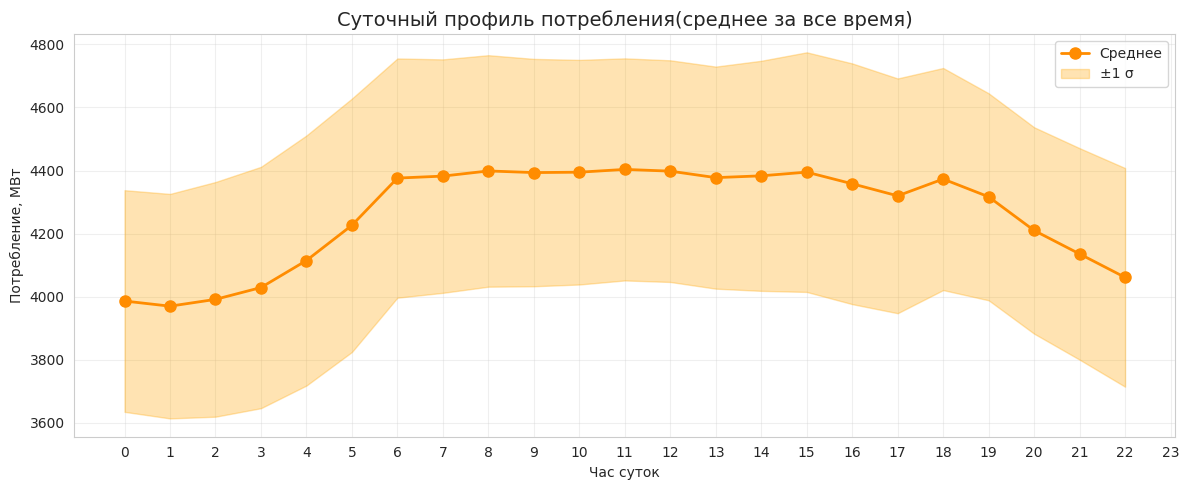

In [9]:
# ============ EDA: СУТОЧНАЯ СЕЗОННОСТЬ ============
hourly_profile = df.groupby(df.index.hour)['actual_consumption'].agg(['mean', 'std'])

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(hourly_profile.index, hourly_profile['mean'],
        'o-', color='darkorange', linewidth=2, markersize=8, label='Среднее')
ax.fill_between(hourly_profile.index,
                hourly_profile['mean'] - hourly_profile['std'],
                hourly_profile['mean'] + hourly_profile['std'],
                alpha=0.3, color='orange', label='±1 σ')
ax.set_title('Суточный профиль потребления(среднее за все время)', fontsize=14)
ax.set_xlabel('Час суток')
ax.set_ylabel('Потребление, МВт')
ax.set_xticks(range(0, 24))
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('eda_daily.png', dpi=150, bbox_inches='tight')
plt.show()

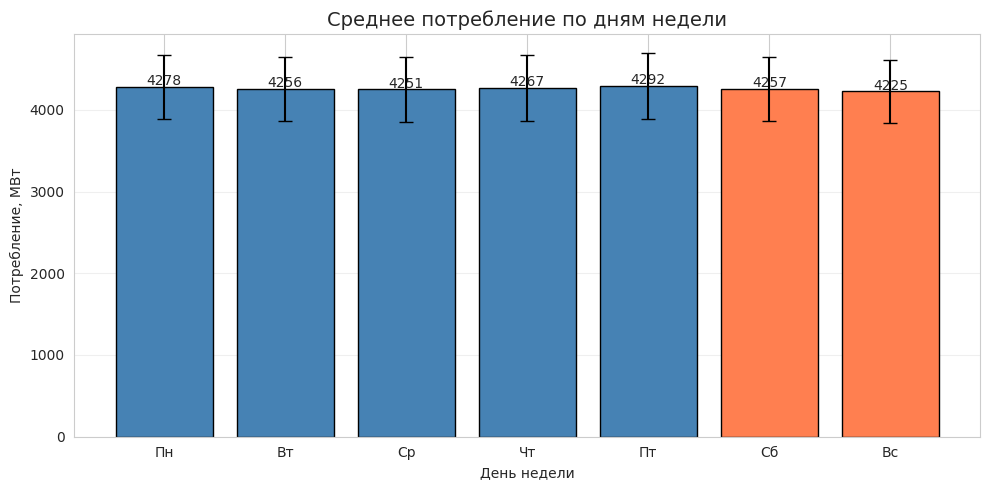

In [10]:
# ============ EDA: НЕДЕЛЬНАЯ СЕЗОННОСТЬ ============
dow_profile = df.groupby(df.index.dayofweek)['actual_consumption'].agg(['mean', 'std'])
day_names = ['Пн', 'Вт', 'Ср', 'Чт', 'Пт', 'Сб', 'Вс']

fig, ax = plt.subplots(figsize=(10, 5))
bars = ax.bar(day_names, dow_profile['mean'].values,
              yerr=dow_profile['std'].values,
              color=['steelblue']*5 + ['coral']*2,
              edgecolor='black', capsize=5)
ax.set_title('Среднее потребление по дням недели', fontsize=14)
ax.set_xlabel('День недели')
ax.set_ylabel('Потребление, МВт')
ax.grid(True, alpha=0.3, axis='y')

for bar, val in zip(bars, dow_profile['mean'].values):
    ax.text(bar.get_x() + bar.get_width()/2, val + 20,
            f'{val:.0f}', ha='center', fontsize=10)

plt.tight_layout()
plt.savefig('eda_weekly.png', dpi=150, bbox_inches='tight')
plt.show()

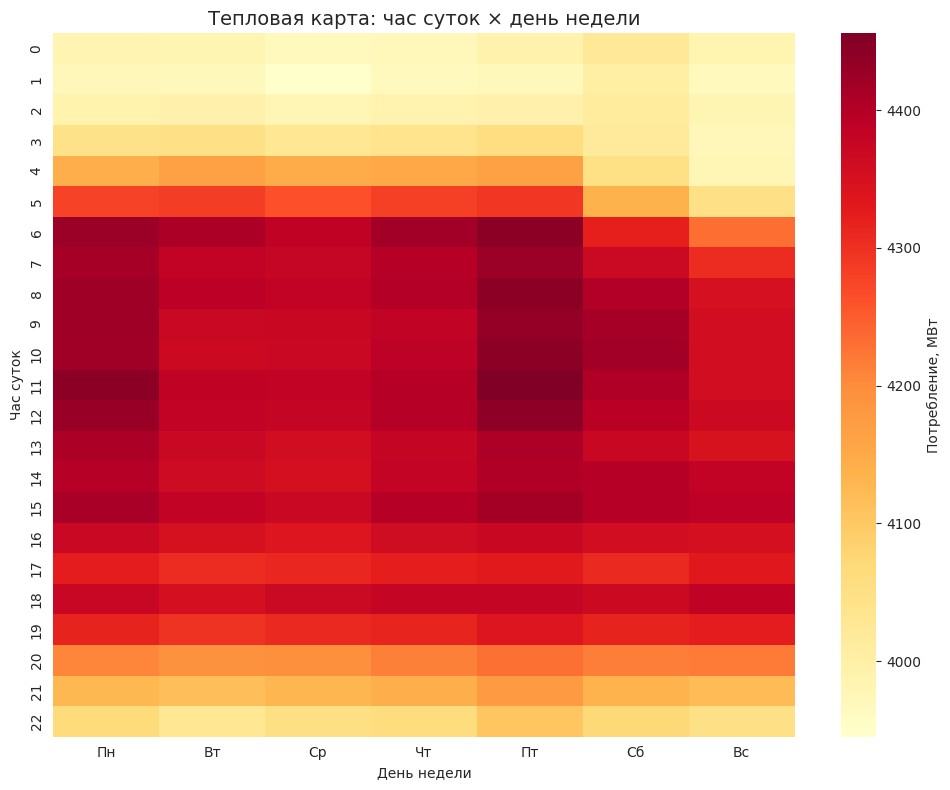

In [11]:
# ============ EDA: ТЕПЛОВАЯ КАРТА ============
pivot = df.pivot_table(
    values='actual_consumption',
    index=df.index.hour,
    columns=df.index.dayofweek,
    aggfunc='mean'
)
pivot.columns = day_names

fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(pivot, cmap='YlOrRd', annot=False,
            cbar_kws={'label': 'Потребление, МВт'}, ax=ax)
ax.set_title('Тепловая карта: час суток × день недели', fontsize=14)
ax.set_xlabel('День недели')
ax.set_ylabel('Час суток')
plt.tight_layout()
plt.savefig('eda_heatmap.png', dpi=150, bbox_inches='tight')
plt.show()

In [12]:

# ============ ПРИЗНАКИ ============
features = [
    'hour', 'dayofweek', 'month', 'dayofyear', 'is_weekend', 'is_holiday',
    'load_lag_1', 'load_lag_2', 'load_lag_24', 'load_lag_48', 'load_lag_168',
    'price_lag_1', 'price_lag_24', 'average_price',
    'gen_lag_1', 'gen_lag_24', 'actual_generation',
    'rolling_mean_24', 'rolling_std_24', 'rolling_max_24', 'rolling_min_24',
    'diff_1', 'diff_24', 'deviation_from_mean',
]

X = df[features]
y = df[target]

# ============ СОЗДАЕМ СПИСОК УНИКАЛЬНЫХ ДНЕЙ ============
unique_days = np.array(sorted(df.index.normalize().unique()))
print(f"Всего дней в данных: {len(unique_days)}")
print(f"Признаков: {len(features)}")
print(f"Строк:     {len(X)}")

Всего дней в данных: 1720
Признаков: 24
Строк:     39546


In [13]:
# ============================================================
# WALK-FORWARD (Rolling Origin по дням)
# ============================================================
print("Начинаем Walk-Forward валидацию (Rolling Origin)...")
start_time = time.time()
step = 0
all_predictions, all_actuals, all_dates = [], [], []

for i, train_day_idx in rolling_origin(unique_days, window_days=None):
    step += 1
    target_day = unique_days[i]

    # 1. Берем все дни до текущего для обучения
    train_days = unique_days[train_day_idx]
    train_mask = df.index.normalize().isin(train_days)
    train_df = df[train_mask]

    # 2. Берем 24 часа текущего дня для теста
    test_mask = df.index.normalize() == target_day
    test_df_wf = df[test_mask]

    if len(test_df_wf) == 0:
        continue

    # 3. Обучение
    model_wf = lgb.LGBMRegressor(
        n_estimators=150, learning_rate=0.05, max_depth=7,
        num_leaves=31, random_state=42, verbose=-1, n_jobs=-1
    )
    model_wf.fit(train_df[features], train_df[target])

    # 4. Прогноз
    preds = model_wf.predict(test_df_wf[features])
    all_predictions.extend(preds)
    all_actuals.extend(test_df_wf[target].values)
    all_dates.extend(test_df_wf.index)

    if step % 30 == 0:
        print(f"Шаг {step} ({target_day.date()}): прошло {(time.time() - start_time)/60:.1f} мин")

print(f"Walk-Forward завершен! Дней спрогнозировано: {step}")

# Сборка результатов
wf_results = pd.DataFrame({'actual': all_actuals, 'predicted': all_predictions}, index=all_dates)
wf_results['planned'] = df.loc[all_dates, 'planned_consumption'].values

# Тестовый период — весь 2025 год
test_period = wf_results
y_test = test_period['actual']
y_pred = test_period['predicted'].values
y_test_abs_arr = y_test.values
plan_test = test_period['planned'].values
X_test = df.loc[test_period.index, features]

# Финальная модель (для важности признаков и прогноза на завтра)
final_model = lgb.LGBMRegressor(n_estimators=500, learning_rate=0.03, max_depth=7, random_state=42, verbose=-1)
final_model.fit(df[features], df[target])
model = final_model

print(f"Тестовый период: {test_period.index.min()} — {test_period.index.max()}")

Начинаем Walk-Forward валидацию (Rolling Origin)...
Шаг 30 (2025-01-30): прошло 0.3 мин
Шаг 60 (2025-03-01): прошло 0.7 мин
Шаг 90 (2025-03-31): прошло 1.0 мин
Шаг 120 (2025-04-30): прошло 1.4 мин
Шаг 150 (2025-05-30): прошло 1.7 мин
Шаг 180 (2025-06-29): прошло 2.1 мин
Шаг 210 (2025-07-29): прошло 2.5 мин
Шаг 240 (2025-08-28): прошло 2.8 мин
Шаг 270 (2025-09-27): прошло 3.2 мин
Шаг 300 (2025-10-27): прошло 3.6 мин
Шаг 330 (2025-11-26): прошло 4.0 мин
Шаг 360 (2025-12-26): прошло 4.4 мин
Walk-Forward завершен! Дней спрогнозировано: 365
Тестовый период: 2025-01-01 00:00:00 — 2025-12-31 22:00:00


ТОП-15 ВАЖНЫХ ПРИЗНАКОВ
            feature  importance
               hour        3170
deviation_from_mean        1196
          dayofyear        1066
         load_lag_1         848
    rolling_mean_24         749
             diff_1         746
            diff_24         692
          dayofweek         630
        load_lag_24         593
         load_lag_2         577
      average_price         571
     rolling_std_24         566
       price_lag_24         457
       load_lag_168         443
  actual_generation         436


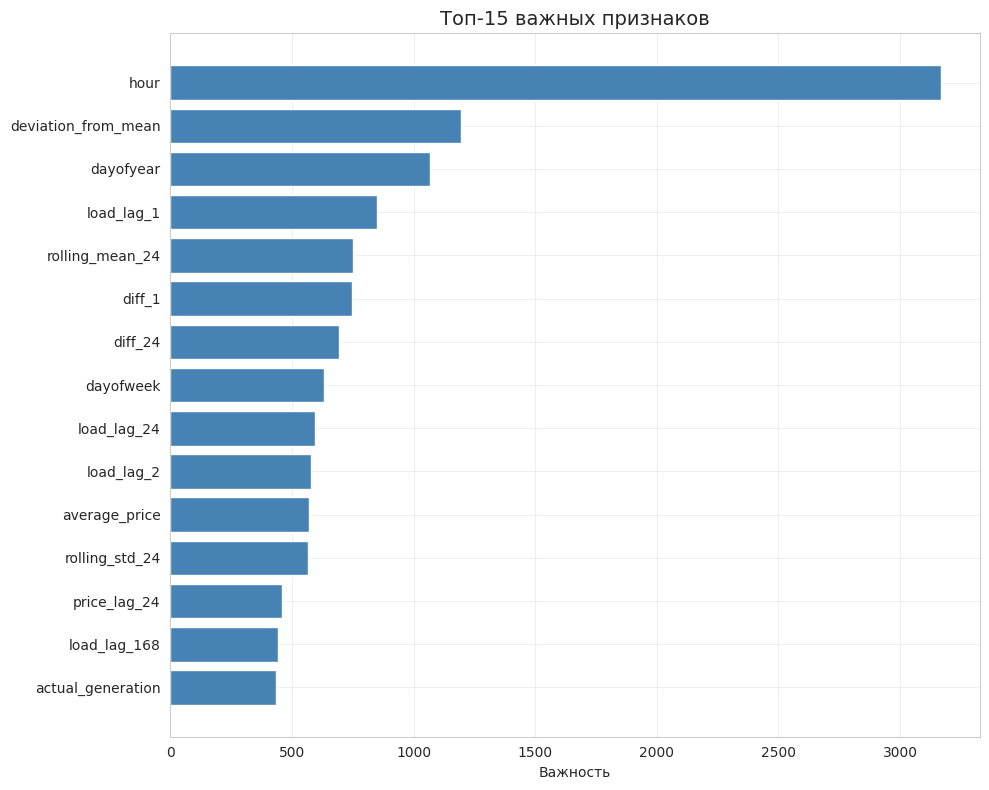

In [14]:
# ============ ВАЖНОСТЬ ПРИЗНАКОВ ============
importance = pd.DataFrame({
    'feature': features,
    'importance': model.feature_importances_
}).sort_values('importance', ascending=False)

print("ТОП-15 ВАЖНЫХ ПРИЗНАКОВ")
print("=" * 60)
print(importance.head(15).to_string(index=False))

fig, ax = plt.subplots(figsize=(10, 8))
top = importance.head(15)
ax.barh(top['feature'][::-1], top['importance'][::-1], color='steelblue')
ax.set_title('Топ-15 важных признаков', fontsize=14)
ax.set_xlabel('Важность')
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('importance.png', dpi=150, bbox_inches='tight')
plt.show()

In [15]:
# ============ ПРОГНОЗ И МЕТРИКИ ============
y_pred = model.predict(X_test)
y_test_abs_arr = y_test.values

mae = mean_absolute_error(y_test_abs_arr, y_pred)
rmse = np.sqrt(mean_squared_error(y_test_abs_arr, y_pred))
r2 = r2_score(y_test_abs_arr, y_pred)

mask = y_test_abs_arr > 0
mape = np.mean(np.abs((y_test_abs_arr[mask] - y_pred[mask]) / y_test_abs_arr[mask])) * 100

plan_test = df.loc[X_test.index, 'planned_consumption'].values
plan_mae = mean_absolute_error(y_test_abs_arr, plan_test)
plan_rmse = np.sqrt(mean_squared_error(y_test_abs_arr, plan_test))
plan_mape = np.mean(np.abs((y_test_abs_arr - plan_test) / y_test_abs_arr)) * 100

In [16]:
# ============ ПРОГНОЗ ПИКОВОГО ЧАСА ============
test_df = pd.DataFrame({
    'actual': y_test_abs_arr,
    'predicted': y_pred
}, index=y_test.index)

test_df = test_df.reset_index()

if 'date' not in test_df.columns:
    test_df = test_df.rename(columns={test_df.columns[0]: 'date'})

test_df['day'] = test_df['date'].dt.date

daily_peaks = test_df.groupby('day').apply(
    lambda x: pd.Series({
        'actual_peak_hour': x.loc[x['actual'].idxmax(), 'date'].hour,
        'predicted_peak_hour': x.loc[x['predicted'].idxmax(), 'date'].hour,
    }),
    include_groups=False
)

daily_peaks['correct'] = daily_peaks['actual_peak_hour'] == daily_peaks['predicted_peak_hour']
daily_peaks['error_hours'] = (daily_peaks['actual_peak_hour'] - daily_peaks['predicted_peak_hour']).abs()

accuracy = daily_peaks['correct'].mean()
accuracy_1h = (daily_peaks['error_hours'] <= 1).mean()
accuracy_2h = (daily_peaks['error_hours'] <= 2).mean()


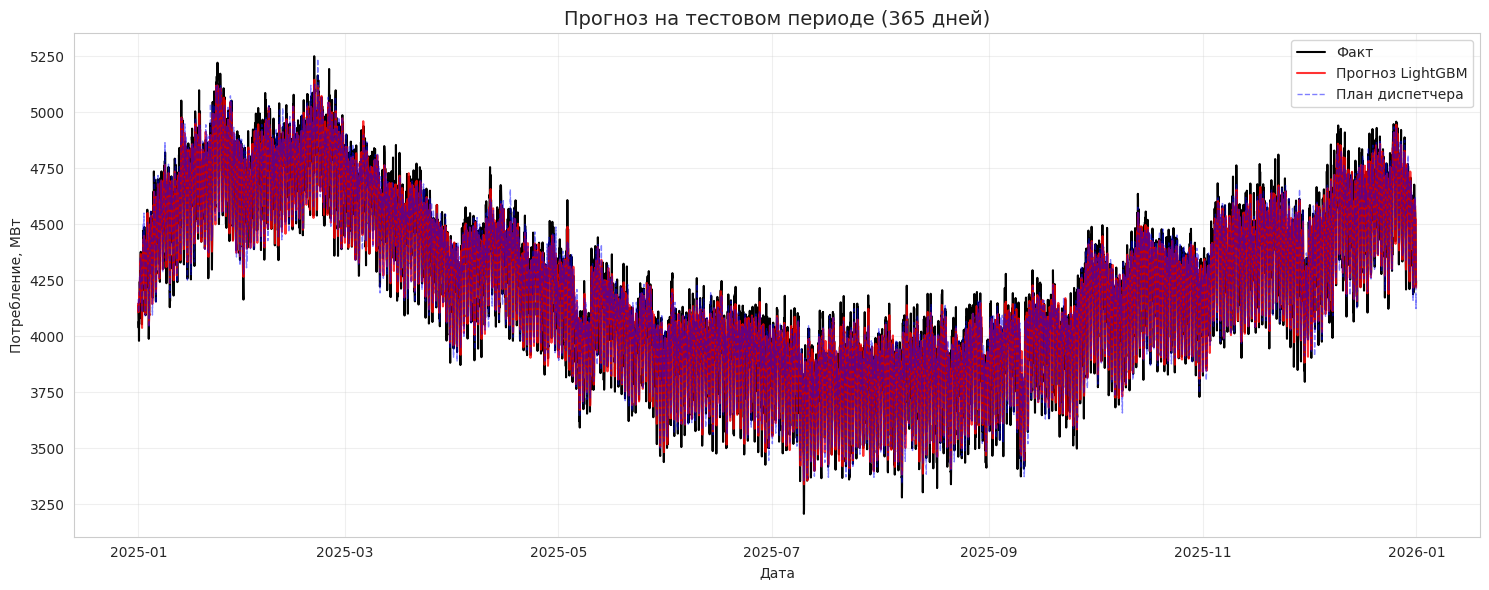

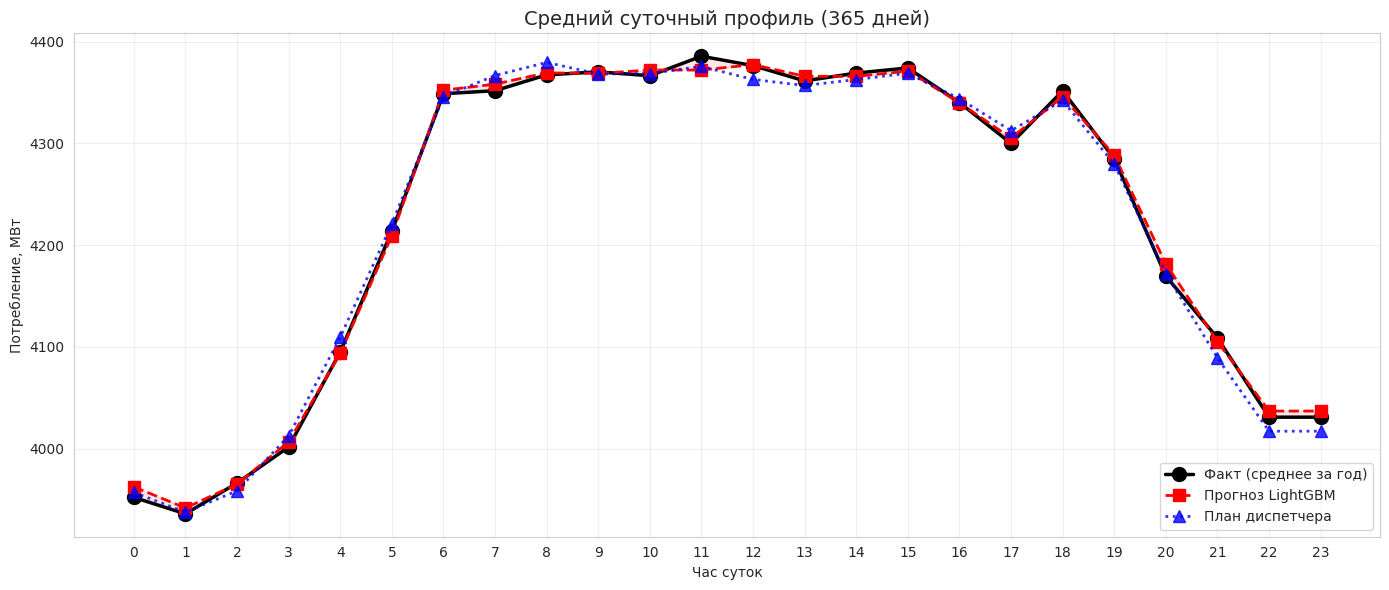

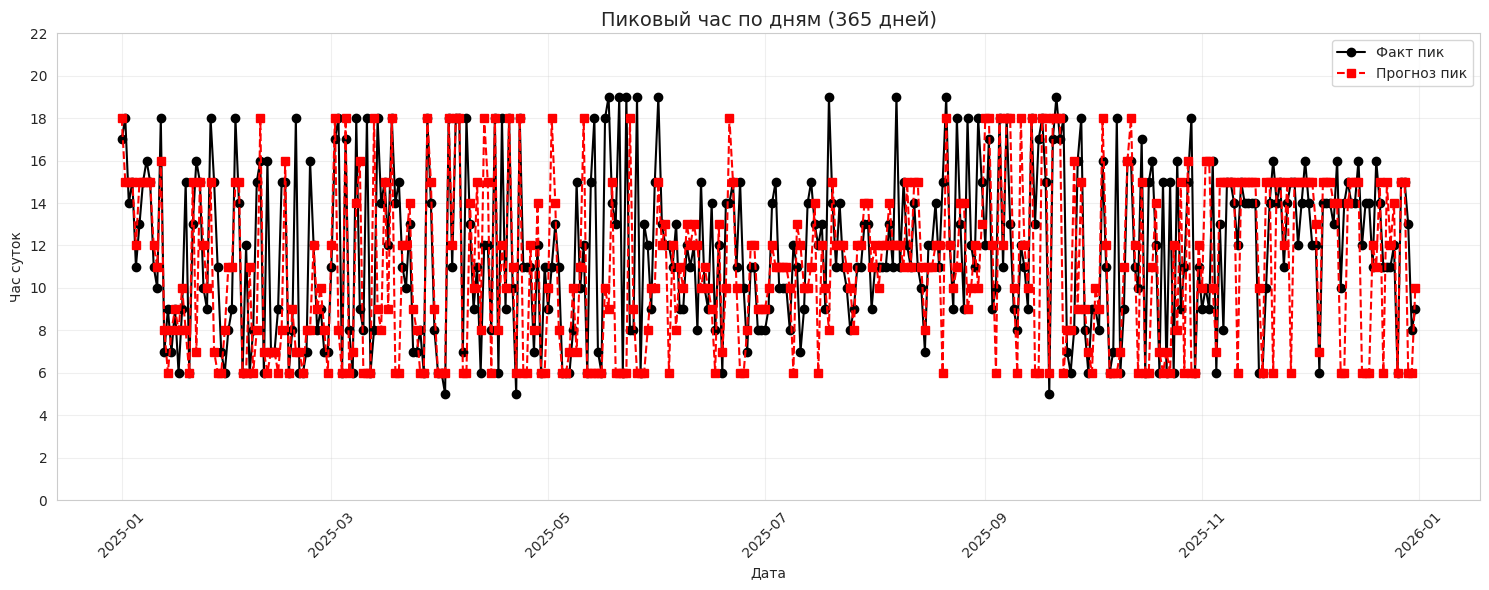


КАЧЕСТВО МОДЕЛИ (СРАВНЕНИЕ С ПЛАНОМ)
Метрика               План     Модель    Улучшение
--------------------------------------------------
MAE, МВт             57.91      51.51       +11.0%
RMSE, МВт            73.11      64.84       +11.3%
MAPE, %               1.38       1.23       +11.0%
R²                       —     0.9702            —

ПРОГНОЗ ПИКОВОГО ЧАСА
Точное совпадение:      14.5%
С допуском ±1 час:      55.6%
С допуском ±2 часа:     66.8%
Среднее отклонение:     2.80 ч
Медиана отклонения:     1.00 ч


In [17]:
# ============ ВИЗУАЛИЗАЦИЯ ============
fig, ax = plt.subplots(figsize=(15, 6))
ax.plot(X_test.index, y_test_abs_arr, label='Факт', linewidth=1.5, color='black')
ax.plot(X_test.index, y_pred, label='Прогноз LightGBM', linewidth=1.5, color='red', alpha=0.8)
ax.plot(X_test.index, plan_test, label='План диспетчера',
        linewidth=1, color='blue', alpha=0.5, linestyle='--')
ax.set_title('Прогноз на тестовом периоде (365 дней)', fontsize=14)
ax.set_xlabel('Дата')
ax.set_ylabel('Потребление, МВт')
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


year_df = pd.DataFrame({
    'actual': y_test_abs_arr,
    'predicted': y_pred,
    'planned': plan_test,
}, index=X_test.index)
year_df['hour'] = year_df.index.hour

yearly_hourly = year_df.groupby('hour').agg(
    actual_mean=('actual', 'mean'),
    predicted_mean=('predicted', 'mean'),
    planned_mean=('planned', 'mean'),
).reindex(range(24)).interpolate(method='linear')

fig, ax = plt.subplots(figsize=(14, 6))
ax.plot(yearly_hourly.index, yearly_hourly['actual_mean'],
        'o-', color='black', linewidth=2.5, markersize=10,
        label='Факт (среднее за год)')
ax.plot(yearly_hourly.index, yearly_hourly['predicted_mean'],
        's--', color='red', linewidth=2, markersize=9,
        label='Прогноз LightGBM')
ax.plot(yearly_hourly.index, yearly_hourly['planned_mean'],
        '^:', color='blue', linewidth=2, markersize=9,
        alpha=0.8, label='План диспетчера')
ax.fill_between(yearly_hourly.index,
                yearly_hourly['actual_mean'],
                yearly_hourly['predicted_mean'],
                color='red', alpha=0.1)
ax.set_title('Средний суточный профиль (365 дней)', fontsize=14)
ax.set_xlabel('Час суток')
ax.set_ylabel('Потребление, МВт')
ax.set_xticks(range(0, 24))
ax.legend(loc='lower right')
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


fig, ax = plt.subplots(figsize=(15, 6))
ax.plot(daily_peaks.index, daily_peaks['actual_peak_hour'],
        'o-', label='Факт пик', markersize=6, color='black')
ax.plot(daily_peaks.index, daily_peaks['predicted_peak_hour'],
        's--', label='Прогноз пик', markersize=6, color='red')
ax.set_title('Пиковый час по дням (365 дней)', fontsize=14)
ax.set_xlabel('Дата')
ax.set_ylabel('Час суток')
ax.set_yticks(range(0, 24, 2))
ax.legend()
ax.grid(True, alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# ============ ТЕКСТОВЫЕ ВЫВОДЫ ============
print("\nКАЧЕСТВО МОДЕЛИ (СРАВНЕНИЕ С ПЛАНОМ)")
print("=" * 60)
print(f"{'Метрика':<15} {'План':>10} {'Модель':>10} {'Улучшение':>12}")
print("-" * 50)
print(f"{'MAE, МВт':<15} {plan_mae:>10.2f} {mae:>10.2f} {(1-mae/plan_mae)*100:>+11.1f}%")
print(f"{'RMSE, МВт':<15} {plan_rmse:>10.2f} {rmse:>10.2f} {(1-rmse/plan_rmse)*100:>+11.1f}%")
print(f"{'MAPE, %':<15} {plan_mape:>10.2f} {mape:>10.2f} {(1-mape/plan_mape)*100:>+11.1f}%")
print(f"{'R²':<15} {'—':>10} {r2:>10.4f} {'—':>12}")

print("\n" + "=" * 60)
print("ПРОГНОЗ ПИКОВОГО ЧАСА")
print("=" * 60)
print(f"Точное совпадение:      {accuracy*100:.1f}%")
print(f"С допуском ±1 час:      {accuracy_1h*100:.1f}%")
print(f"С допуском ±2 часа:     {accuracy_2h*100:.1f}%")
print(f"Среднее отклонение:     {daily_peaks['error_hours'].mean():.2f} ч")
print(f"Медиана отклонения:     {daily_peaks['error_hours'].median():.2f} ч")

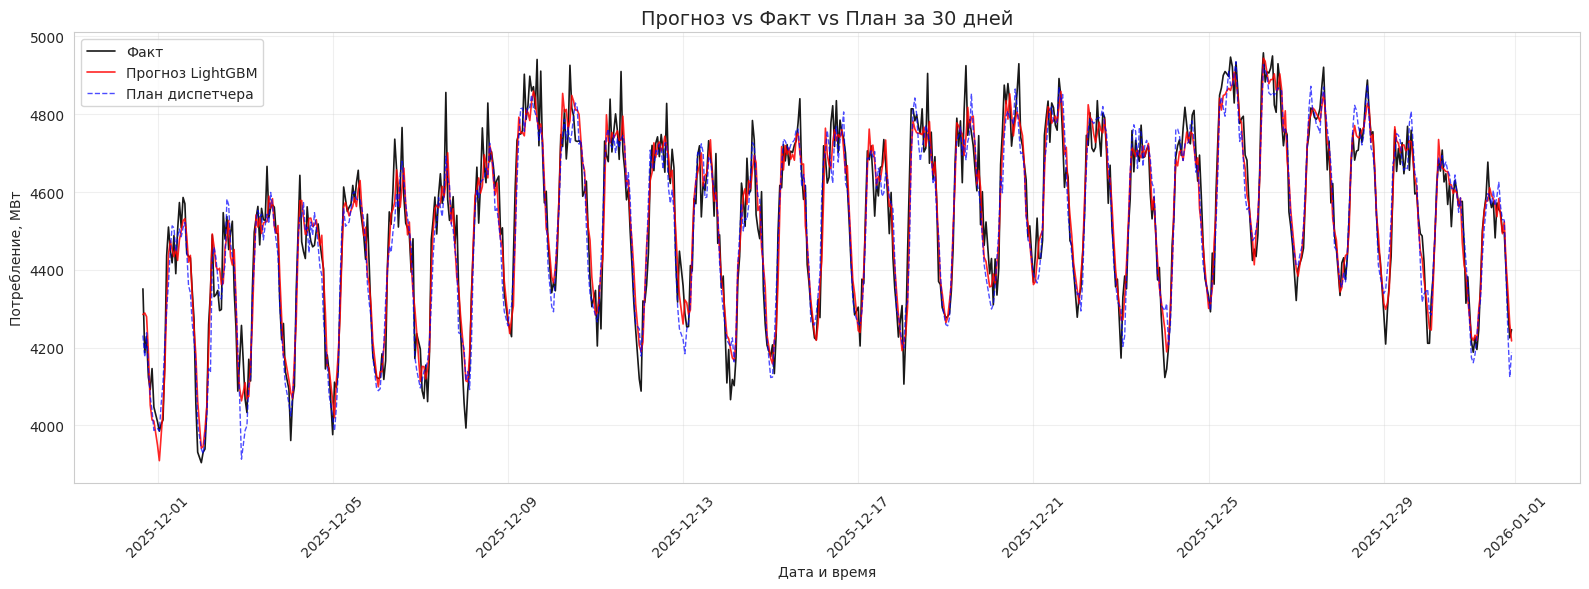

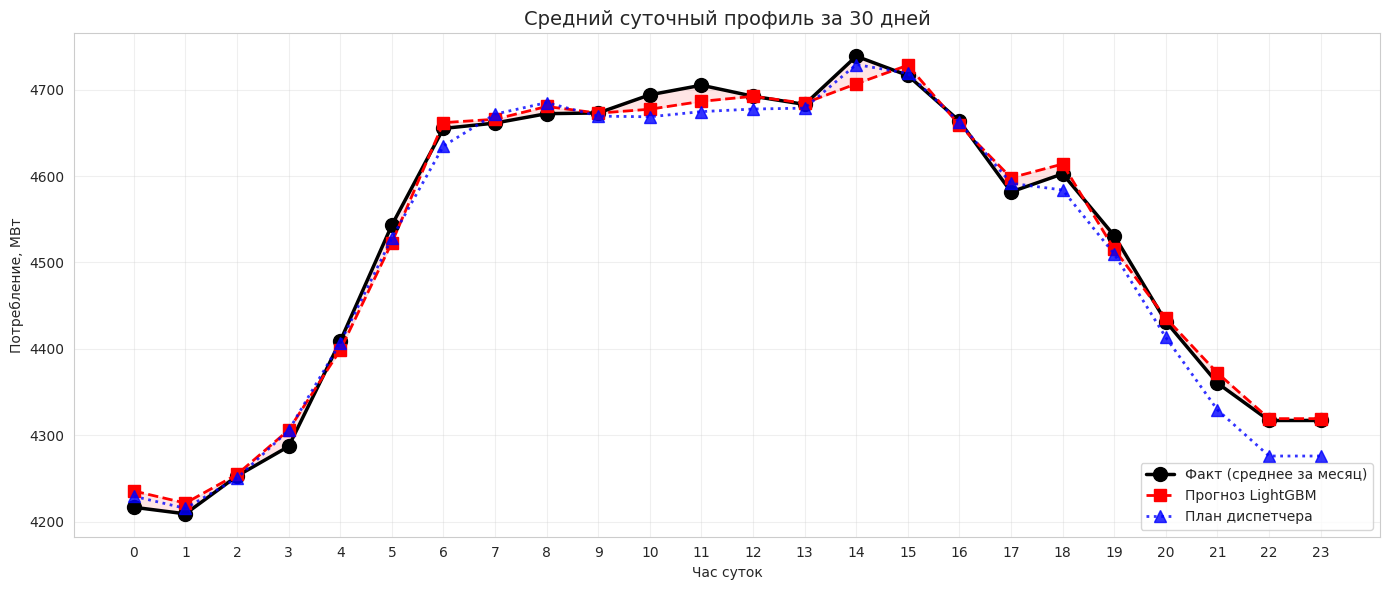

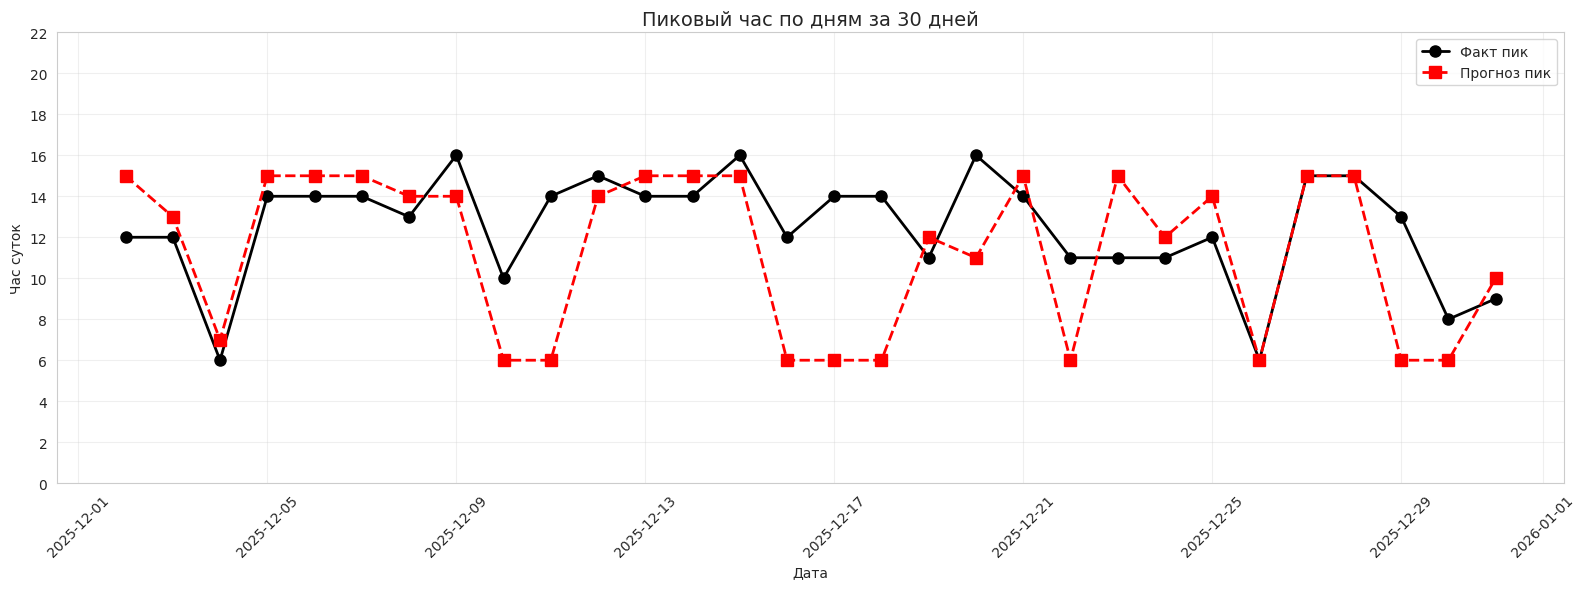


МЕТРИКИ ЗА 30 ДНЕЙ

Метрика                 План       Модель      Улучшение
-------------------------------------------------------
MAE, МВт               55.93        51.30          +8.3%
RMSE, МВт              71.62        64.49          +9.9%
MAPE, %                 1.24         1.14          +8.3%
R²                         —       0.9169              —

ПРОГНОЗ ПИКОВОГО ЧАСА ЗА 30 ДНЕЙ
Точное совпадение:      10.0%
С допуском ±1 час:      56.7%
С допуском ±2 часа:     66.7%
Среднее отклонение:     2.60 ч
Медиана отклонения:     1.00 ч


In [18]:
# ============================================================
# 16.1. АНАЛИЗ ЗА МЕСЯЦ
# ============================================================
last_month_hours = 720
y_test_month = y_test_abs_arr[-last_month_hours:]
y_pred_month = y_pred[-last_month_hours:]
plan_test_month = plan_test[-last_month_hours:]
index_month = X_test.index[-last_month_hours:]

month_df = pd.DataFrame({
    'actual': y_test_month,
    'predicted': y_pred_month,
    'planned': plan_test_month,
}, index=index_month)

month_df.index.name = None
month_df['error'] = month_df['predicted'] - month_df['actual']
month_df['abs_error'] = month_df['error'].abs()
month_df['hour'] = month_df.index.hour
month_df['day'] = month_df.index.date
month_df['dayofweek'] = month_df.index.dayofweek


# ============================================================
# ГРАФИК 1: ПРОГНОЗ VS ФАКТ VS ПЛАН
# ============================================================
fig, ax = plt.subplots(figsize=(16, 6))

ax.plot(month_df.index, month_df['actual'],
        '-', color='black', linewidth=1.2, label='Факт', alpha=0.9)
ax.plot(month_df.index, month_df['predicted'],
        '-', color='red', linewidth=1.2, label='Прогноз LightGBM', alpha=0.85)
ax.plot(month_df.index, month_df['planned'],
        '--', color='blue', linewidth=1, alpha=0.7, label='План диспетчера')

ax.set_title('Прогноз vs Факт vs План за 30 дней', fontsize=14)
ax.set_xlabel('Дата и время')
ax.set_ylabel('Потребление, МВт')
ax.legend(loc='upper left')
ax.grid(True, alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# ============================================================
# СРЕДНИЙ СУТОЧНЫЙ ПРОФИЛЬ
# ============================================================
monthly_hourly = month_df.groupby('hour').agg(
    actual_mean=('actual', 'mean'),
    predicted_mean=('predicted', 'mean'),
    planned_mean=('planned', 'mean'),
).reindex(range(24)).interpolate(method='linear')

fig, ax = plt.subplots(figsize=(14, 6))

ax.plot(monthly_hourly.index, monthly_hourly['actual_mean'],
        'o-', color='black', linewidth=2.5, markersize=10,
        label='Факт (среднее за месяц)')
ax.plot(monthly_hourly.index, monthly_hourly['predicted_mean'],
        's--', color='red', linewidth=2, markersize=9,
        label='Прогноз LightGBM')
ax.plot(monthly_hourly.index, monthly_hourly['planned_mean'],
        '^:', color='blue', linewidth=2, markersize=9,
        alpha=0.8, label='План диспетчера')

ax.fill_between(monthly_hourly.index,
                monthly_hourly['actual_mean'],
                monthly_hourly['predicted_mean'],
                color='red', alpha=0.1)

ax.set_title('Средний суточный профиль за 30 дней', fontsize=14)
ax.set_xlabel('Час суток')
ax.set_ylabel('Потребление, МВт')
ax.set_xticks(range(0, 24))
ax.legend(loc='lower right')
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# ============================================================
# ГРАФИК ПИКОВЫХ ЧАСОВ
# ============================================================
last_30_peaks = daily_peaks.iloc[-30:]

fig, ax = plt.subplots(figsize=(16, 6))

ax.plot(last_30_peaks.index, last_30_peaks['actual_peak_hour'],
        'o-', label='Факт пик', markersize=8, color='black', linewidth=2)
ax.plot(last_30_peaks.index, last_30_peaks['predicted_peak_hour'],
        's--', label='Прогноз пик', markersize=8, color='red', linewidth=2)

ax.set_title('Пиковый час по дням за 30 дней', fontsize=14)
ax.set_xlabel('Дата')
ax.set_ylabel('Час суток')
ax.set_yticks(range(0, 24, 2))
ax.legend()
ax.grid(True, alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# ============================================================
# ТЕКСТ: МЕТРИКИ ЗА ВЕСЬ МЕСЯЦ
# ============================================================
print("\n" + "=" * 60)
print("МЕТРИКИ ЗА 30 ДНЕЙ")
print("=" * 60)

mae_m = month_df['abs_error'].mean()
rmse_m = np.sqrt((month_df['error'] ** 2).mean())
mape_m = (month_df['abs_error'] / month_df['actual']).mean() * 100

plan_error_m = month_df['planned'] - month_df['actual']
mae_plan_m = plan_error_m.abs().mean()
rmse_plan_m = np.sqrt((plan_error_m ** 2).mean())
mape_plan_m = (plan_error_m.abs() / month_df['actual']).mean() * 100

r2_m = 1 - (month_df['error']**2).sum() / ((month_df['actual'] - month_df['actual'].mean())**2).sum()

print(f"\n{'Метрика':<15} {'План':>12} {'Модель':>12} {'Улучшение':>14}")
print("-" * 55)
print(f"{'MAE, МВт':<15} {mae_plan_m:>12.2f} {mae_m:>12.2f} {(1-mae_m/mae_plan_m)*100:>+13.1f}%")
print(f"{'RMSE, МВт':<15} {rmse_plan_m:>12.2f} {rmse_m:>12.2f} {(1-rmse_m/rmse_plan_m)*100:>+13.1f}%")
print(f"{'MAPE, %':<15} {mape_plan_m:>12.2f} {mape_m:>12.2f} {(1-mape_m/mape_plan_m)*100:>+13.1f}%")
print(f"{'R²':<15} {'—':>12} {r2_m:>12.4f} {'—':>14}")

# ============================================================
# СТАТИСТИКА ПИКОВОГО ЧАСА ЗА ПОСЛЕДНИЕ
# ============================================================
print("\n" + "=" * 60)
print("ПРОГНОЗ ПИКОВОГО ЧАСА ЗА 30 ДНЕЙ")
print("=" * 60)

last_30_peaks = daily_peaks.iloc[-30:].copy()

acc_30 = last_30_peaks['correct'].mean()
acc_1h_30 = (last_30_peaks['error_hours'] <= 1).mean()
acc_2h_30 = (last_30_peaks['error_hours'] <= 2).mean()

print(f"Точное совпадение:      {acc_30*100:.1f}%")
print(f"С допуском ±1 час:      {acc_1h_30*100:.1f}%")
print(f"С допуском ±2 часа:     {acc_2h_30*100:.1f}%")
print(f"Среднее отклонение:     {last_30_peaks['error_hours'].mean():.2f} ч")
print(f"Медиана отклонения:     {last_30_peaks['error_hours'].median():.2f} ч")


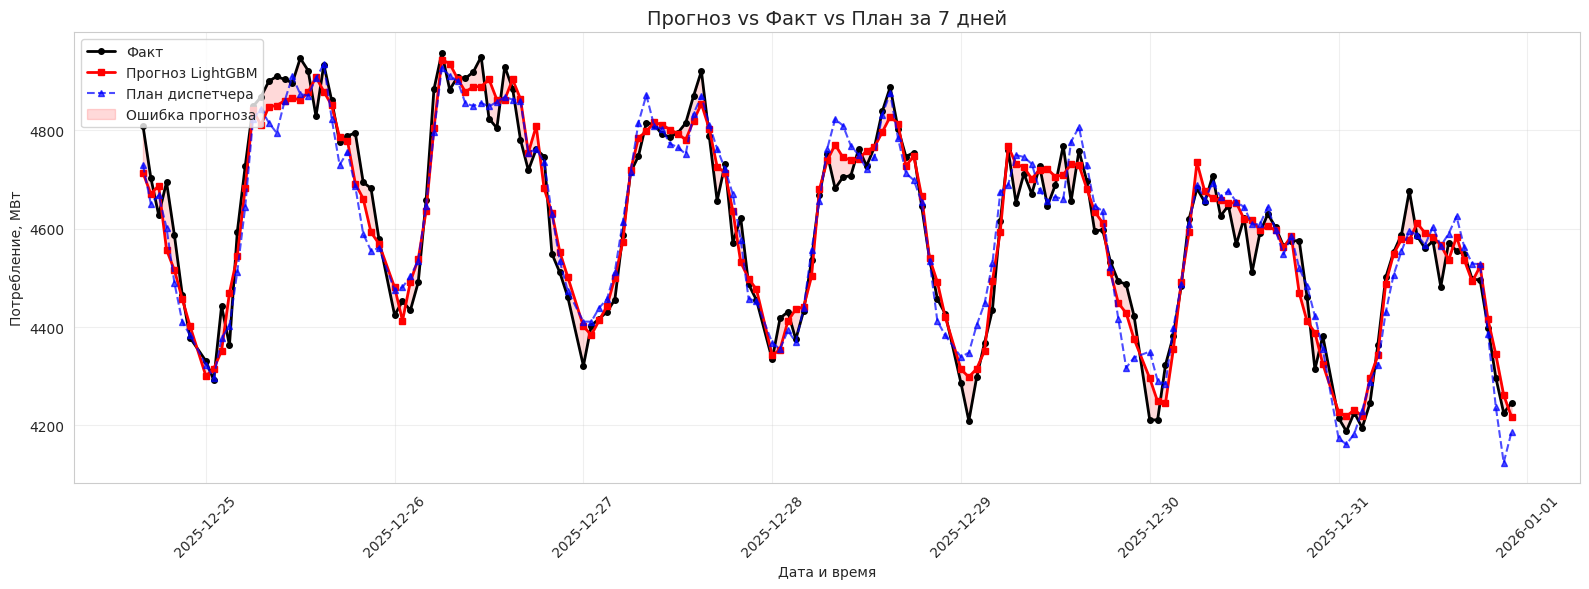

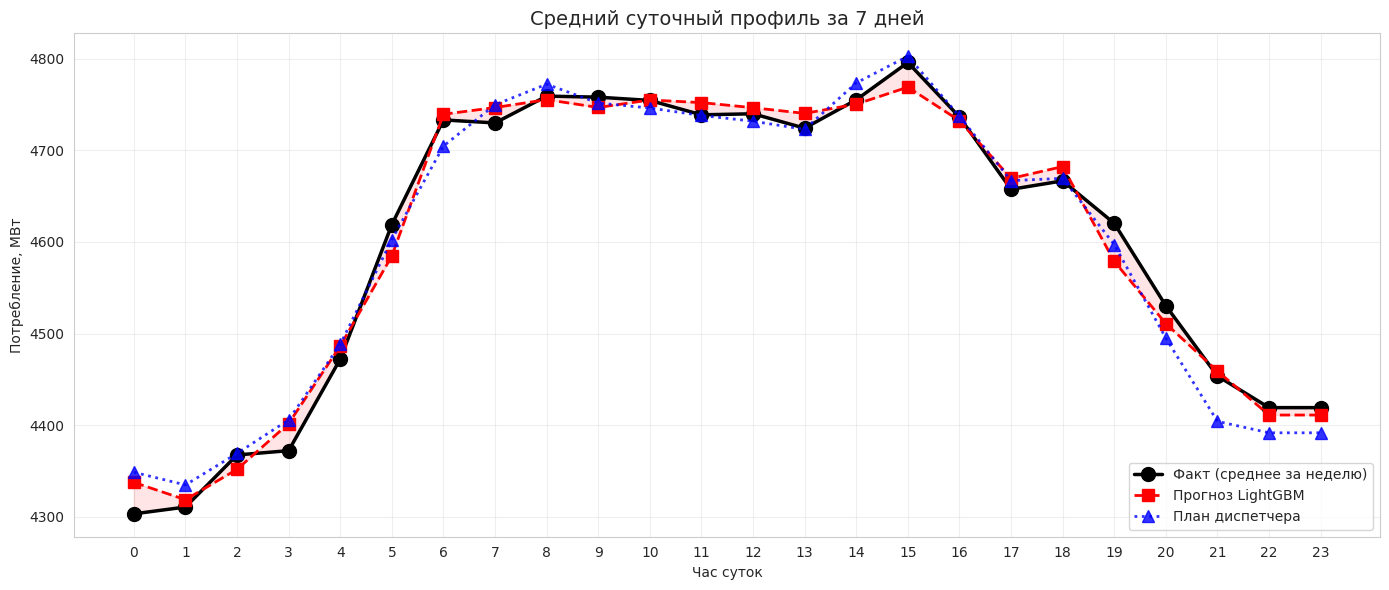

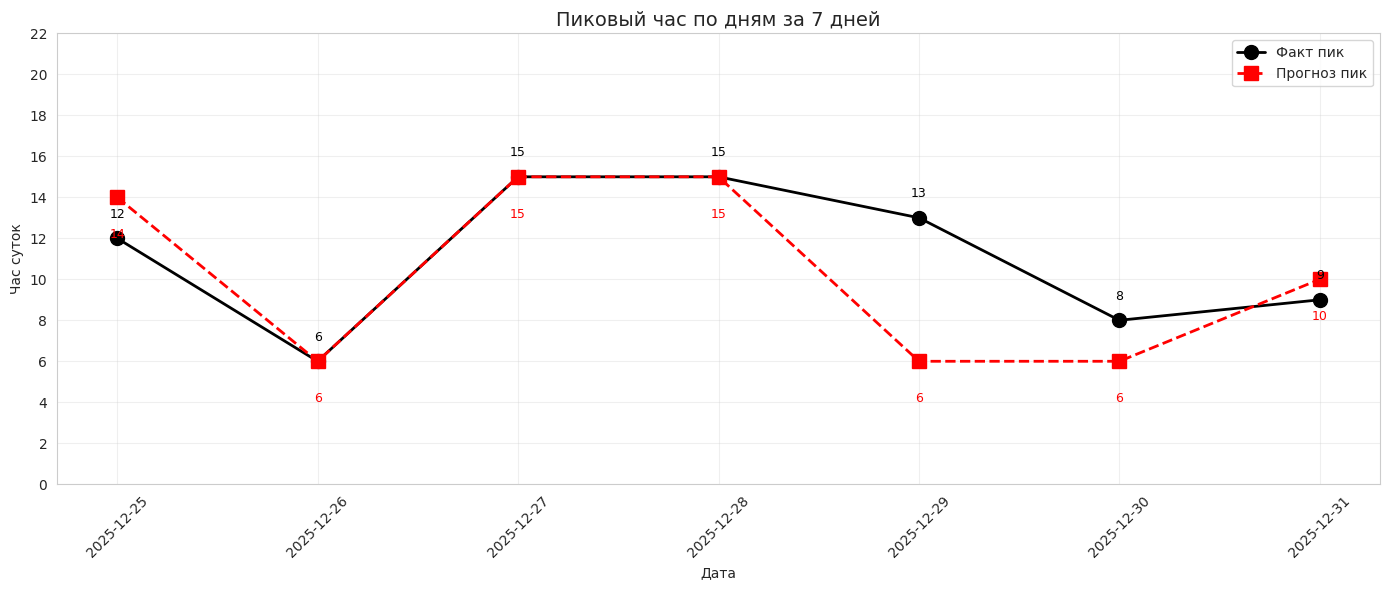


МЕТРИКИ ЗА ПОСЛЕДНЮЮ НЕДЕЛЮ

Метрика                 План       Модель      Улучшение
-------------------------------------------------------
MAE, МВт               46.29        38.62         +16.6%
RMSE, МВт              58.21        48.21         +17.2%
MAPE, %                 1.01         0.84         +16.9%
R²                         —       0.9404              —

ПРОГНОЗ ПИКОВОГО ЧАСА ЗА ПОСЛЕДНЮЮ НЕДЕЛЮ
Точное совпадение:      42.9%
С допуском ±1 час:      57.1%
С допуском ±2 часа:     85.7%
Среднее отклонение:     1.71 ч
Медиана отклонения:     1.00 ч


In [19]:
# ============================================================
# ГРАФИК 2: ПРОГНОЗ VS ФАКТ VS ПЛАН — 7 ДНЕЙ
# ============================================================
last_week = month_df.iloc[-168:]

fig, ax = plt.subplots(figsize=(16, 6))

ax.plot(last_week.index, last_week['actual'],
        'o-', color='black', linewidth=2, markersize=4, label='Факт')
ax.plot(last_week.index, last_week['predicted'],
        's-', color='red', linewidth=2, markersize=4, label='Прогноз LightGBM')
ax.plot(last_week.index, last_week['planned'],
        '^--', color='blue', linewidth=1.5, markersize=4,
        alpha=0.7, label='План диспетчера')

ax.fill_between(last_week.index,
                last_week['actual'], last_week['predicted'],
                color='red', alpha=0.15, label='Ошибка прогноза')

ax.set_title('Прогноз vs Факт vs План за 7 дней', fontsize=14)
ax.set_xlabel('Дата и время')
ax.set_ylabel('Потребление, МВт')
ax.legend(loc='upper left')
ax.grid(True, alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# ============================================================
# СРЕДНИЙ СУТОЧНЫЙ ПРОФИЛЬ ЗА 7 ДНЕЙ
# ============================================================
weekly_hourly = last_week.groupby('hour').agg(
    actual_mean=('actual', 'mean'),
    predicted_mean=('predicted', 'mean'),
    planned_mean=('planned', 'mean'),
).reindex(range(24)).interpolate(method='linear')

fig, ax = plt.subplots(figsize=(14, 6))

ax.plot(weekly_hourly.index, weekly_hourly['actual_mean'],
        'o-', color='black', linewidth=2.5, markersize=10,
        label='Факт (среднее за неделю)')
ax.plot(weekly_hourly.index, weekly_hourly['predicted_mean'],
        's--', color='red', linewidth=2, markersize=9,
        label='Прогноз LightGBM')
ax.plot(weekly_hourly.index, weekly_hourly['planned_mean'],
        '^:', color='blue', linewidth=2, markersize=9,
        alpha=0.8, label='План диспетчера')

ax.fill_between(weekly_hourly.index,
                weekly_hourly['actual_mean'],
                weekly_hourly['predicted_mean'],
                color='red', alpha=0.1)

ax.set_title('Средний суточный профиль за 7 дней', fontsize=14)
ax.set_xlabel('Час суток')
ax.set_ylabel('Потребление, МВт')
ax.set_xticks(range(0, 24))
ax.legend(loc='lower right')
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# ============================================================
# ГРАФИК ПИКОВОГО ЧАСА ЗА ПОСЛЕДНЮЮ НЕДЕЛЮ
# ============================================================
fig, ax = plt.subplots(figsize=(14, 6))

last_week_peaks_plot = daily_peaks.iloc[-7:]

ax.plot(last_week_peaks_plot.index, last_week_peaks_plot['actual_peak_hour'],
        'o-', label='Факт пик', markersize=10, color='black', linewidth=2)
ax.plot(last_week_peaks_plot.index, last_week_peaks_plot['predicted_peak_hour'],
        's--', label='Прогноз пик', markersize=10, color='red', linewidth=2)

for i, (idx, row) in enumerate(last_week_peaks_plot.iterrows()):
    ax.text(idx, row['actual_peak_hour'] + 1, f"{int(row['actual_peak_hour'])}",
            ha='center', fontsize=9, color='black')
    ax.text(idx, row['predicted_peak_hour'] - 2, f"{int(row['predicted_peak_hour'])}",
            ha='center', fontsize=9, color='red')

ax.set_title('Пиковый час по дням за 7 дней', fontsize=14)
ax.set_xlabel('Дата')
ax.set_ylabel('Час суток')
ax.set_yticks(range(0, 24, 2))
ax.legend()
ax.grid(True, alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# ============================================================
# ТЕКСТ: МЕТРИКИ ЗА НЕДЕЛЮ
# ============================================================
print("\n" + "=" * 60)
print("МЕТРИКИ ЗА ПОСЛЕДНЮЮ НЕДЕЛЮ")
print("=" * 60)

mae_w = last_week['abs_error'].mean()
rmse_w = np.sqrt((last_week['error'] ** 2).mean())
mape_w = (last_week['abs_error'] / last_week['actual']).mean() * 100

plan_error_w = last_week['planned'] - last_week['actual']
mae_plan_w = plan_error_w.abs().mean()
rmse_plan_w = np.sqrt((plan_error_w ** 2).mean())
mape_plan_w = (plan_error_w.abs() / last_week['actual']).mean() * 100

r2_w = 1 - (last_week['error']**2).sum() / ((last_week['actual'] - last_week['actual'].mean())**2).sum()

print(f"\n{'Метрика':<15} {'План':>12} {'Модель':>12} {'Улучшение':>14}")
print("-" * 55)
print(f"{'MAE, МВт':<15} {mae_plan_w:>12.2f} {mae_w:>12.2f} {(1-mae_w/mae_plan_w)*100:>+13.1f}%")
print(f"{'RMSE, МВт':<15} {rmse_plan_w:>12.2f} {rmse_w:>12.2f} {(1-rmse_w/rmse_plan_w)*100:>+13.1f}%")
print(f"{'MAPE, %':<15} {mape_plan_w:>12.2f} {mape_w:>12.2f} {(1-mape_w/mape_plan_w)*100:>+13.1f}%")
print(f"{'R²':<15} {'—':>12} {r2_w:>12.4f} {'—':>14}")

# ============================================================
# СТАТИСТИКА ПИКОВОГО ЧАСА ЗА ПОСЛЕДНЮЮ НЕДЕЛЮ
# ============================================================
print("\n" + "=" * 60)
print("ПРОГНОЗ ПИКОВОГО ЧАСА ЗА ПОСЛЕДНЮЮ НЕДЕЛЮ")
print("=" * 60)

last_week_peaks = daily_peaks.iloc[-7:].copy()

acc_week = last_week_peaks['correct'].mean()
acc_1h_week = (last_week_peaks['error_hours'] <= 1).mean()
acc_2h_week = (last_week_peaks['error_hours'] <= 2).mean()

print(f"Точное совпадение:      {acc_week*100:.1f}%")
print(f"С допуском ±1 час:      {acc_1h_week*100:.1f}%")
print(f"С допуском ±2 часа:     {acc_2h_week*100:.1f}%")
print(f"Среднее отклонение:     {last_week_peaks['error_hours'].mean():.2f} ч")
print(f"Медиана отклонения:     {last_week_peaks['error_hours'].median():.2f} ч")

In [20]:
# Принудительно создаем test_df с планом, если его нет
test_df = pd.DataFrame({
    'actual': y_test_abs_arr,
    'predicted': y_pred,
    'planned': plan_test  # <--- Вот эту колонку мы добавляем
}, index=X_test.index)

test_df = test_df.reset_index()
test_df['day'] = test_df['index'].dt.date

In [22]:
# ============ ПРОГНОЗ ПИКОВОГО ЧАСА (МОДЕЛЬ VS ДИСПЕТЧЕР) ============
# Считаем пики для Факта, Модели и Плана
plan_df = pd.DataFrame({
    'actual': y_test_abs_arr,
    'predicted': y_pred,
    'planned': plan_test
}, index=X_test.index)

# Создаем колонку с датой
plan_df['day'] = plan_df.index.date

daily_peaks = plan_df.groupby('day').apply(
    lambda x: pd.Series({
        'actual_peak_hour': x.loc[x['actual'].idxmax(), :].name.hour,
        'model_peak_hour': x.loc[x['predicted'].idxmax(), :].name.hour,
        'plan_peak_hour': x.loc[x['planned'].idxmax(), :].name.hour,
    }),
    include_groups=False
)

# --- 1. Точность МОДЕЛИ ---
daily_peaks['model_correct'] = daily_peaks['actual_peak_hour'] == daily_peaks['model_peak_hour']
daily_peaks['model_error'] = (daily_peaks['actual_peak_hour'] - daily_peaks['model_peak_hour']).abs()

acc_model = daily_peaks['model_correct'].mean()
acc_model_1h = (daily_peaks['model_error'] <= 1).mean()
acc_model_2h = (daily_peaks['model_error'] <= 2).mean()

# --- 2. Точность ДИСПЕТЧЕРА (Плана) ---
daily_peaks['plan_correct'] = daily_peaks['actual_peak_hour'] == daily_peaks['plan_peak_hour']
daily_peaks['plan_error'] = (daily_peaks['actual_peak_hour'] - daily_peaks['plan_peak_hour']).abs()

acc_plan = daily_peaks['plan_correct'].mean()
acc_plan_1h = (daily_peaks['plan_error'] <= 1).mean()
acc_plan_2h = (daily_peaks['plan_error'] <= 2).mean()

# --- 3. Вывод результатов ---
print("=" * 60)
print("ТОЧНОСТЬ ПРОГНОЗА ПИКОВОГО ЧАСА (2025 ГОД)")
print("=" * 60)
print(f"{'Показатель':<25} {'Диспетчер':>15} {'Модель':>15} {'Улучшение':>15}")
print("-" * 70)

# Точное совпадение
impr_acc = acc_model - acc_plan
print(f"{'Точное совпадение:':<25} {acc_plan*100:>14.1f}% {acc_model*100:>14.1f}% {impr_acc*100:>+14.1f}%")

# Допуск ±1 час
impr_1h = acc_model_1h - acc_plan_1h
print(f"{'С допуском ±1 час:':<25} {acc_plan_1h*100:>14.1f}% {acc_model_1h*100:>14.1f}% {impr_1h*100:>+14.1f}%")

# Допуск ±2 часа
impr_2h = acc_model_2h - acc_plan_2h
print(f"{'С допуском ±2 часа:':<25} {acc_plan_2h*100:>14.1f}% {acc_model_2h*100:>14.1f}% {impr_2h*100:>+14.1f}%")

# Среднее отклонение (чем меньше, тем лучше)
mean_err_plan = daily_peaks['plan_error'].mean()
mean_err_model = daily_peaks['model_error'].mean()
print(f"{'Среднее отклонение (ч):':<25} {mean_err_plan:>14.2f} {mean_err_model:>14.2f} {mean_err_plan - mean_err_model:>+14.2f}")

# Медиана отклонения
med_err_plan = daily_peaks['plan_error'].median()
med_err_model = daily_peaks['model_error'].median()
print(f"{'Медиана отклонения (ч):':<25} {med_err_plan:>14.2f} {med_err_model:>14.2f} {med_err_plan - med_err_model:>+14.2f}")

# Сохраняем пики для графиков
daily_peaks.rename(columns={'model_peak_hour': 'predicted_peak_hour'}, inplace=True)

ТОЧНОСТЬ ПРОГНОЗА ПИКОВОГО ЧАСА (2025 ГОД)
Показатель                      Диспетчер          Модель       Улучшение
----------------------------------------------------------------------
Точное совпадение:                  14.2%           14.5%           +0.3%
С допуском ±1 час:                  35.3%           55.6%          +20.3%
С допуском ±2 часа:                 52.3%           66.8%          +14.5%
Среднее отклонение (ч):             3.49           2.80          +0.69
Медиана отклонения (ч):             2.00           1.00          +1.00


ПРОГНОЗ НА СЛЕДУЮЩИЕ 24 ЧАСА
Последняя дата в данных: 2026-09-23 19:00:00
Прогноз на: 2026-09-23 20:00:00 — 2026-09-24 19:00:00

ПРОГНОЗ ПОТРЕБЛЕНИЯ НА СЛЕДУЮЩИЕ 24 ЧАСА
           datetime  predicted_consumption_MW  planned_consumption_MW  hour
2026-09-23 20:00:00                   3913.20                 4215.82    20
2026-09-23 21:00:00                   3896.88                 4124.22    21
2026-09-23 22:00:00                   3866.76                 4046.74    22
2026-09-23 23:00:00                   3869.62                 4251.00    23
2026-09-24 00:00:00                   3912.61                 3988.09     0
2026-09-24 01:00:00                   3938.25                 3970.06     1
2026-09-24 02:00:00                   3979.37                 3984.93     2
2026-09-24 03:00:00                   3998.99                 4038.25     3
2026-09-24 04:00:00                   4060.48                 4134.08     4
2026-09-24 05:00:00                   4098.58                 4245.30 

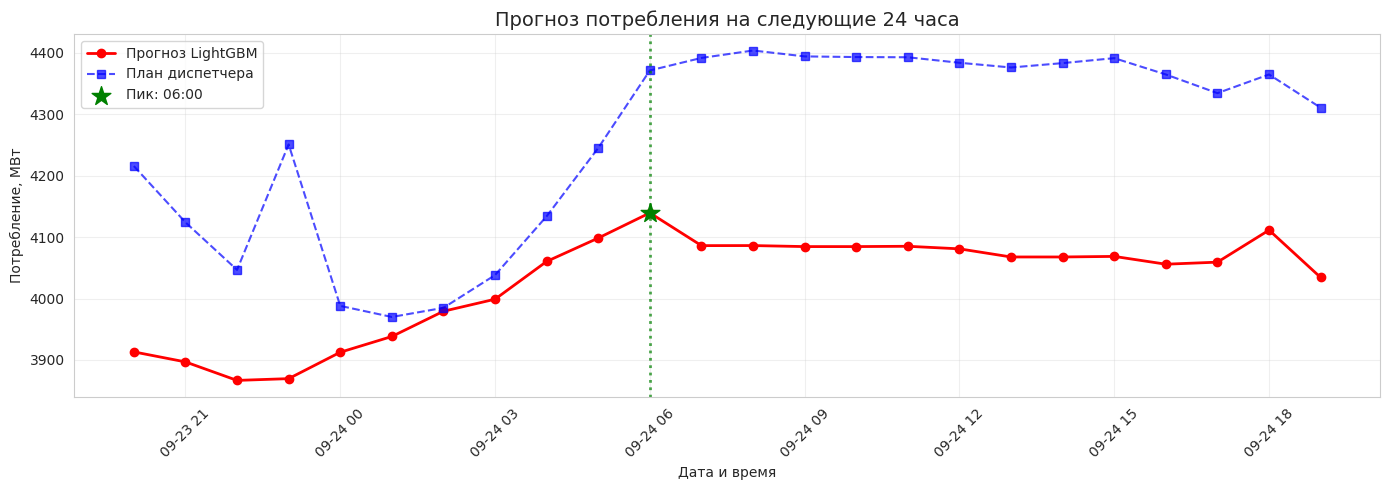


Сохранено:
  forecast_tomorrow.csv
  forecast_tomorrow.png


In [23]:
# ============ ПРОГНОЗ НА ЗАВТРА (РЕАЛЬНОЕ ВРЕМЯ) ============
from datetime import datetime, timedelta
import warnings
warnings.filterwarnings('ignore')

print("=" * 60)
print("ПРОГНОЗ НА СЛЕДУЮЩИЕ 24 ЧАСА")
print("=" * 60)

last_date = df.index.max()
print(f"Последняя дата в данных: {last_date}")

future_dates = pd.date_range(
    start=last_date + pd.Timedelta(hours=1),
    periods=24,
    freq='H'
)
print(f"Прогноз на: {future_dates.min()} — {future_dates.max()}")

future = pd.DataFrame(index=future_dates)

future['hour'] = future.index.hour
future['dayofweek'] = future.index.dayofweek
future['month'] = future.index.month
future['dayofyear'] = future.index.dayofyear
future['is_weekend'] = (future.index.dayofweek >= 5).astype(int)

ru_holidays = holidays.Russia(years=future.index.year.unique())
ru_holidays_set = pd.to_datetime(list(ru_holidays.keys()))
future['is_holiday'] = future.index.normalize().isin(ru_holidays_set).astype(int)

last_24h = df.iloc[-24:]

for col in ['planned_consumption', 'planned_generation',
            'average_price', 'actual_generation']:
    hourly_avg = df.groupby(df.index.hour)[col].mean()
    future[col] = future.index.hour.map(hourly_avg)

    future[col] = future[col].fillna(df[col].median())

last_values = df.iloc[-1]
last_1h = df.iloc[-1]['actual_consumption']
last_2h = df.iloc[-2]['actual_consumption']
last_24h_val = df.iloc[-24]['actual_consumption']
last_48h_val = df.iloc[-48]['actual_consumption']
last_168h_val = df.iloc[-168]['actual_consumption']

future['load_lag_1'] = last_1h
future['load_lag_2'] = last_2h
future['load_lag_24'] = last_24h_val
future['load_lag_48'] = last_48h_val
future['load_lag_168'] = last_168h_val

future['price_lag_1'] = last_values['average_price']
future['price_lag_24'] = df.iloc[-24]['average_price']

future['planned_lag_1'] = last_values['planned_consumption']
future['planned_lag_24'] = df.iloc[-24]['planned_consumption']

future['gen_lag_1'] = last_values['actual_generation']
future['gen_lag_24'] = df.iloc[-24]['actual_generation']

future['rolling_mean_24'] = last_24h['actual_consumption'].mean()
future['rolling_std_24'] = last_24h['actual_consumption'].std()
future['rolling_max_24'] = last_24h['actual_consumption'].max()
future['rolling_min_24'] = last_24h['actual_consumption'].min()

future['diff_1'] = last_values['actual_consumption'] - df.iloc[-2]['actual_consumption']
future['diff_24'] = last_values['actual_consumption'] - df.iloc[-25]['actual_consumption']
future['deviation_from_mean'] = last_values['actual_consumption'] - future['rolling_mean_24']

future['plan_error_lag_1'] = last_values['planned_consumption'] - last_values['actual_consumption']
future['plan_error_lag_24'] = df.iloc[-24]['planned_consumption'] - df.iloc[-24]['actual_consumption']

X_future = future[features]
y_future_pred = model.predict(X_future)

result = pd.DataFrame({
    'datetime': future_dates,
    'predicted_consumption_MW': y_future_pred.round(2),
    'planned_consumption_MW': future['planned_consumption'].values.round(2),
    'hour': future.index.hour,
})

print("\n" + "=" * 60)
print("ПРОГНОЗ ПОТРЕБЛЕНИЯ НА СЛЕДУЮЩИЕ 24 ЧАСА")
print("=" * 60)
print(result.to_string(index=False))

peak_idx = y_future_pred.argmax()
peak_hour = future_dates[peak_idx]
peak_value = y_future_pred[peak_idx]

print(f"\n Прогнозируемый пиковый час: {peak_hour}")
print(f"   Значение: {peak_value:.0f} МВт")

fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(future_dates, y_future_pred, 'o-', color='red',
        linewidth=2, markersize=6, label='Прогноз LightGBM')
ax.plot(future_dates, future['planned_consumption'].values,
        's--', color='blue', linewidth=1.5, markersize=6,
        alpha=0.7, label='План диспетчера')

ax.axvline(peak_hour, color='green', linestyle=':', linewidth=2, alpha=0.7)
ax.scatter([peak_hour], [peak_value], color='green', s=200,
           zorder=5, marker='*', label=f'Пик: {peak_hour.strftime("%H:%M")}')

ax.set_title('Прогноз потребления на следующие 24 часа', fontsize=14)
ax.set_xlabel('Дата и время')
ax.set_ylabel('Потребление, МВт')
ax.legend()
ax.grid(True, alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

print("\nСохранено:")
print("  forecast_tomorrow.csv")
print("  forecast_tomorrow.png")